
# Visual supports for *Modern Optimizers as Noise-Shaping Mechanisms*


In [1]:

import os
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch, Circle, Rectangle, FancyBboxPatch
from matplotlib import patheffects

# ---------------------------------------------------------------------
# Global style. You can change these once and regenerate every figure.
# ---------------------------------------------------------------------
OUT_DIR = "figures"
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "figure.dpi": 140,
    "savefig.dpi": 240,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

COL = {
    "sgd": "#1f77b4",
    "sde": "#d62728",
    "gd": "#2ca02c",
    "sam": "#9467bd",
    "accent": "#ff7f0e",
    "flat": "#2ca02c",
    "sharp": "#d62728",
    "gray": "#7f7f7f",
    "dark": "#222222",
    "light": "#f7f7f7",
    "purple": "#9467bd",
    "teal": "#17becf",
}


def savefig(fig, name):
    """Save a figure both as PNG and PDF, with a consistent path."""
    png = os.path.join(OUT_DIR, name + ".png")
    pdf = os.path.join(OUT_DIR, name + ".pdf")
    fig.savefig(png, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    print(f"saved: {png}\nsaved: {pdf}")


def add_panel_label(ax, label):
    ax.text(0.01, 0.98, label, transform=ax.transAxes, ha="left", va="top",
            fontsize=11, fontweight="bold",
            path_effects=[patheffects.withStroke(linewidth=3, foreground="white")])


def arrow(ax, xy1, xy2, color="k", lw=1.8, ms=13, ls="-", alpha=1, zorder=5):
    arr = FancyArrowPatch(xy1, xy2, arrowstyle="-|>", mutation_scale=ms,
                          lw=lw, color=color, linestyle=ls, alpha=alpha, zorder=zorder)
    ax.add_patch(arr)
    return arr


def label_box(ax, xy, text, fc="white", ec="#555555", fontsize=9, ha="center", va="center"):
    ax.text(xy[0], xy[1], text, ha=ha, va=va, fontsize=fontsize,
            bbox=dict(boxstyle="round,pad=0.28", fc=fc, ec=ec, lw=0.8, alpha=0.95))


## Figure 1.1


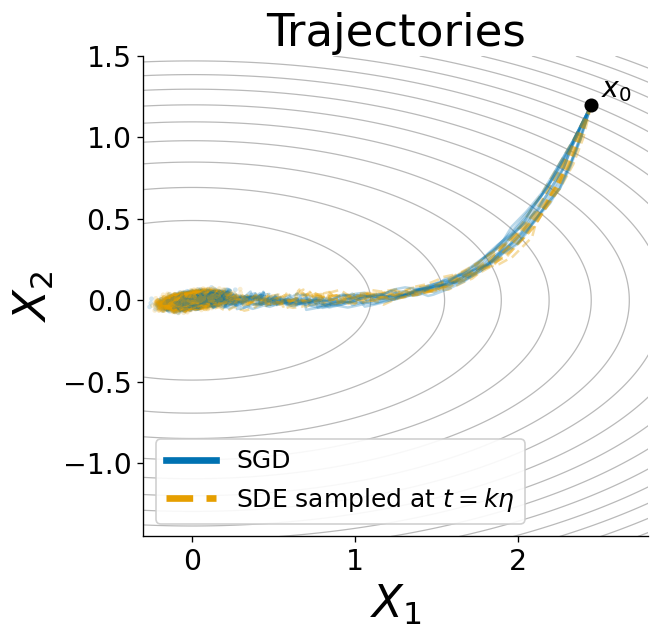

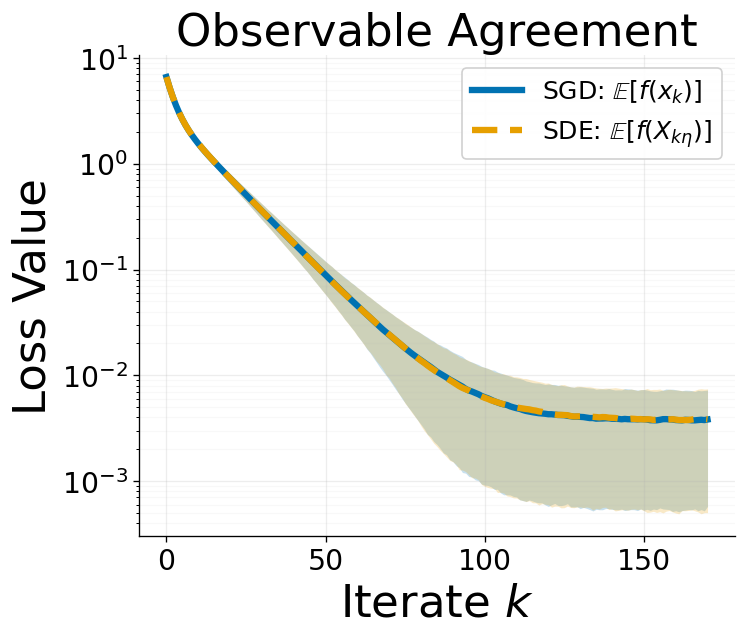

In [2]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def make_fig01_sde_tracks_optimizer_separate(
    seed=11,
    non_gaussian_sgd=True,
    traj_fig_width=6.0,
    traj_fig_height=5.2,
    obs_fig_width=6.4,
    obs_fig_height=5.2,
    dpi=120,
    save_dpi=300,
    out_prefix="fig01_sde_tracks_optimizer",
    show=True,
):
    """
    Saves two separate figures:

      1. {out_prefix}_trajectories.pdf/png
      2. {out_prefix}_observable.pdf/png

    The first figure shows trajectories and terminal clouds.
    The second figure shows observable agreement for the loss.
    """

    rng = np.random.default_rng(seed)

    style = {
        "font.family": "DejaVu Sans",
        "font.size": 17,
        "axes.titlesize": 27,
        "axes.labelsize": 27,
        "xtick.labelsize": 17,
        "ytick.labelsize": 17,
        "legend.fontsize": 15,
        "lines.linewidth": 3.5,
        "axes.linewidth": 0.8,
        "mathtext.fontset": "dejavusans",
        "figure.dpi": dpi,
        "savefig.dpi": save_dpi,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }

    COL = {
        "sgd": "#0072B2",
        "sde": "#E69F00",
        "cloud_sgd": "#0072B2",
        "cloud_sde": "#E69F00",
    }

    with mpl.rc_context(style):
        # ------------------------------------------------------------------
        # Problem setup
        # ------------------------------------------------------------------
        A = np.array([[1.0, 0.0], [0.0, 5.0]])
        Sigma = np.array([[0.30, 0.12], [0.12, 0.12]])
        L = np.linalg.cholesky(Sigma)

        eta = 0.035
        steps = 170
        paths = 8192
        plot_paths = 12
        x0 = np.array([2.45, 1.20])

        def f(x):
            return 0.5 * np.einsum("...i,ij,...j->...", x, A, x)

        def grad(x):
            return x @ A.T

        sgd = np.zeros((paths, steps + 1, 2))
        sde = np.zeros_like(sgd)
        sgd[:, 0, :] = x0
        sde[:, 0, :] = x0

        # ------------------------------------------------------------------
        # Simulate SGD and SDE
        # ------------------------------------------------------------------
        for k in range(steps):
            if non_gaussian_sgd:
                z_sgd = rng.choice([-1.0, 1.0], size=(paths, 2))
            else:
                z_sgd = rng.normal(size=(paths, 2))

            noise_sgd = z_sgd @ L.T
            noise_sde = rng.normal(size=(paths, 2)) @ L.T

            sgd[:, k + 1, :] = sgd[:, k, :] - eta * (grad(sgd[:, k, :]) + noise_sgd)
            sde[:, k + 1, :] = sde[:, k, :] - eta * (grad(sde[:, k, :]) + noise_sde)

        # ==============================================================
        # Figure 1: trajectories and terminal cloud
        # ==============================================================
        fig_traj, ax = plt.subplots(
            1, 1,
            figsize=(traj_fig_width, traj_fig_height),
        )

        xs = np.linspace(-0.30, 2.80, 260)
        ys = np.linspace(-1.45, 1.50, 260)
        X, Y = np.meshgrid(xs, ys)
        Z = 0.5 * (A[0, 0] * X**2 + A[1, 1] * Y**2)

        ax.contour(
            X, Y, Z,
            levels=16,
            colors="0.35",
            linewidths=0.75,
            alpha=0.42,
        )

        for i in range(plot_paths):
            ax.plot(
                sgd[i, :, 0], sgd[i, :, 1],
                color=COL["sgd"], alpha=0.28, lw=1.5,
            )
            ax.plot(
                sde[i, :, 0], sde[i, :, 1],
                color=COL["sde"], alpha=0.36, lw=1.5,
                linestyle=(0, (4.0, 2.0)),
            )

        ax.scatter(
            sgd[:, -1, 0], sgd[:, -1, 1],
            s=8, color=COL["cloud_sgd"], alpha=0.18, edgecolors="none",
        )
        ax.scatter(
            sde[:, -1, 0], sde[:, -1, 1],
            s=8, color=COL["cloud_sde"], alpha=0.18, edgecolors="none",
        )

        ax.scatter([x0[0]], [x0[1]], s=55, color="black", zorder=20)
        ax.text(x0[0] + 0.06, x0[1] + 0.05, r"$x_0$", fontsize=17)

        legend_handles = [
            Line2D([0], [0], color=COL["sgd"], lw=4.0, label="SGD"),
            Line2D(
                [0], [0],
                color=COL["sde"], lw=4.0,
                linestyle=(0, (4.0, 2.0)),
                label=r"SDE sampled at $t=k\eta$",
            ),
        ]

        ax.legend(
            handles=legend_handles,
            loc="lower left",
            frameon=True,
            framealpha=0.90,
            facecolor="white",
            edgecolor="0.80",
        )

        ax.set_title("Trajectories")
        ax.set_xlabel(r"$X_1$")
        ax.set_ylabel(r"$X_2$")
        ax.set_xlim(-0.30, 2.80)
        ax.set_ylim(-1.45, 1.50)
        ax.set_aspect("equal", adjustable="box")

        fig_traj.savefig(f"{out_prefix}_trajectories.pdf", bbox_inches="tight")
        fig_traj.savefig(f"{out_prefix}_trajectories.png", bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close(fig_traj)

        # ==============================================================
        # Figure 2: observable agreement
        # ==============================================================
        fig_obs, ax = plt.subplots(
            1, 1,
            figsize=(obs_fig_width, obs_fig_height),
        )

        k_grid = np.arange(steps + 1)
        sgd_loss = f(sgd)
        sde_loss = f(sde)

        for loss, color, label, ls in [
            (sgd_loss, COL["sgd"], r"SGD: $\mathbb{E}[f(x_k)]$", "-"),
            (sde_loss, COL["sde"], r"SDE: $\mathbb{E}[f(X_{k\eta})]$", (0, (4.0, 2.0))),
        ]:
            mean = loss.mean(axis=0)
            lo = np.quantile(loss, 0.15, axis=0)
            hi = np.quantile(loss, 0.85, axis=0)

            ax.plot(k_grid, mean, color=color, lw=3.8, linestyle=ls, label=label)
            ax.fill_between(k_grid, lo, hi, color=color, alpha=0.22, lw=0)

        ax.set_yscale("log")
        ax.set_title("Observable Agreement")
        ax.set_xlabel(r"Iterate $k$")
        ax.set_ylabel(r"Loss Value")

        ax.legend(
            loc="upper right",
            frameon=True,
            framealpha=0.90,
            facecolor="white",
            edgecolor="0.80",
        )

        ax.grid(True, which="major", alpha=0.22)
        ax.grid(True, which="minor", alpha=0.08)

        fig_obs.savefig(f"{out_prefix}_observable.pdf", bbox_inches="tight")
        fig_obs.savefig(f"{out_prefix}_observable.png", bbox_inches="tight")

        if show:
            plt.show()
        else:
            plt.close(fig_obs)


make_fig01_sde_tracks_optimizer_separate(
    traj_fig_width=6.0,
    traj_fig_height=5.2,
    obs_fig_width=6.4,
    obs_fig_height=5.2,
    non_gaussian_sgd=True,
)

## Figure 2.1

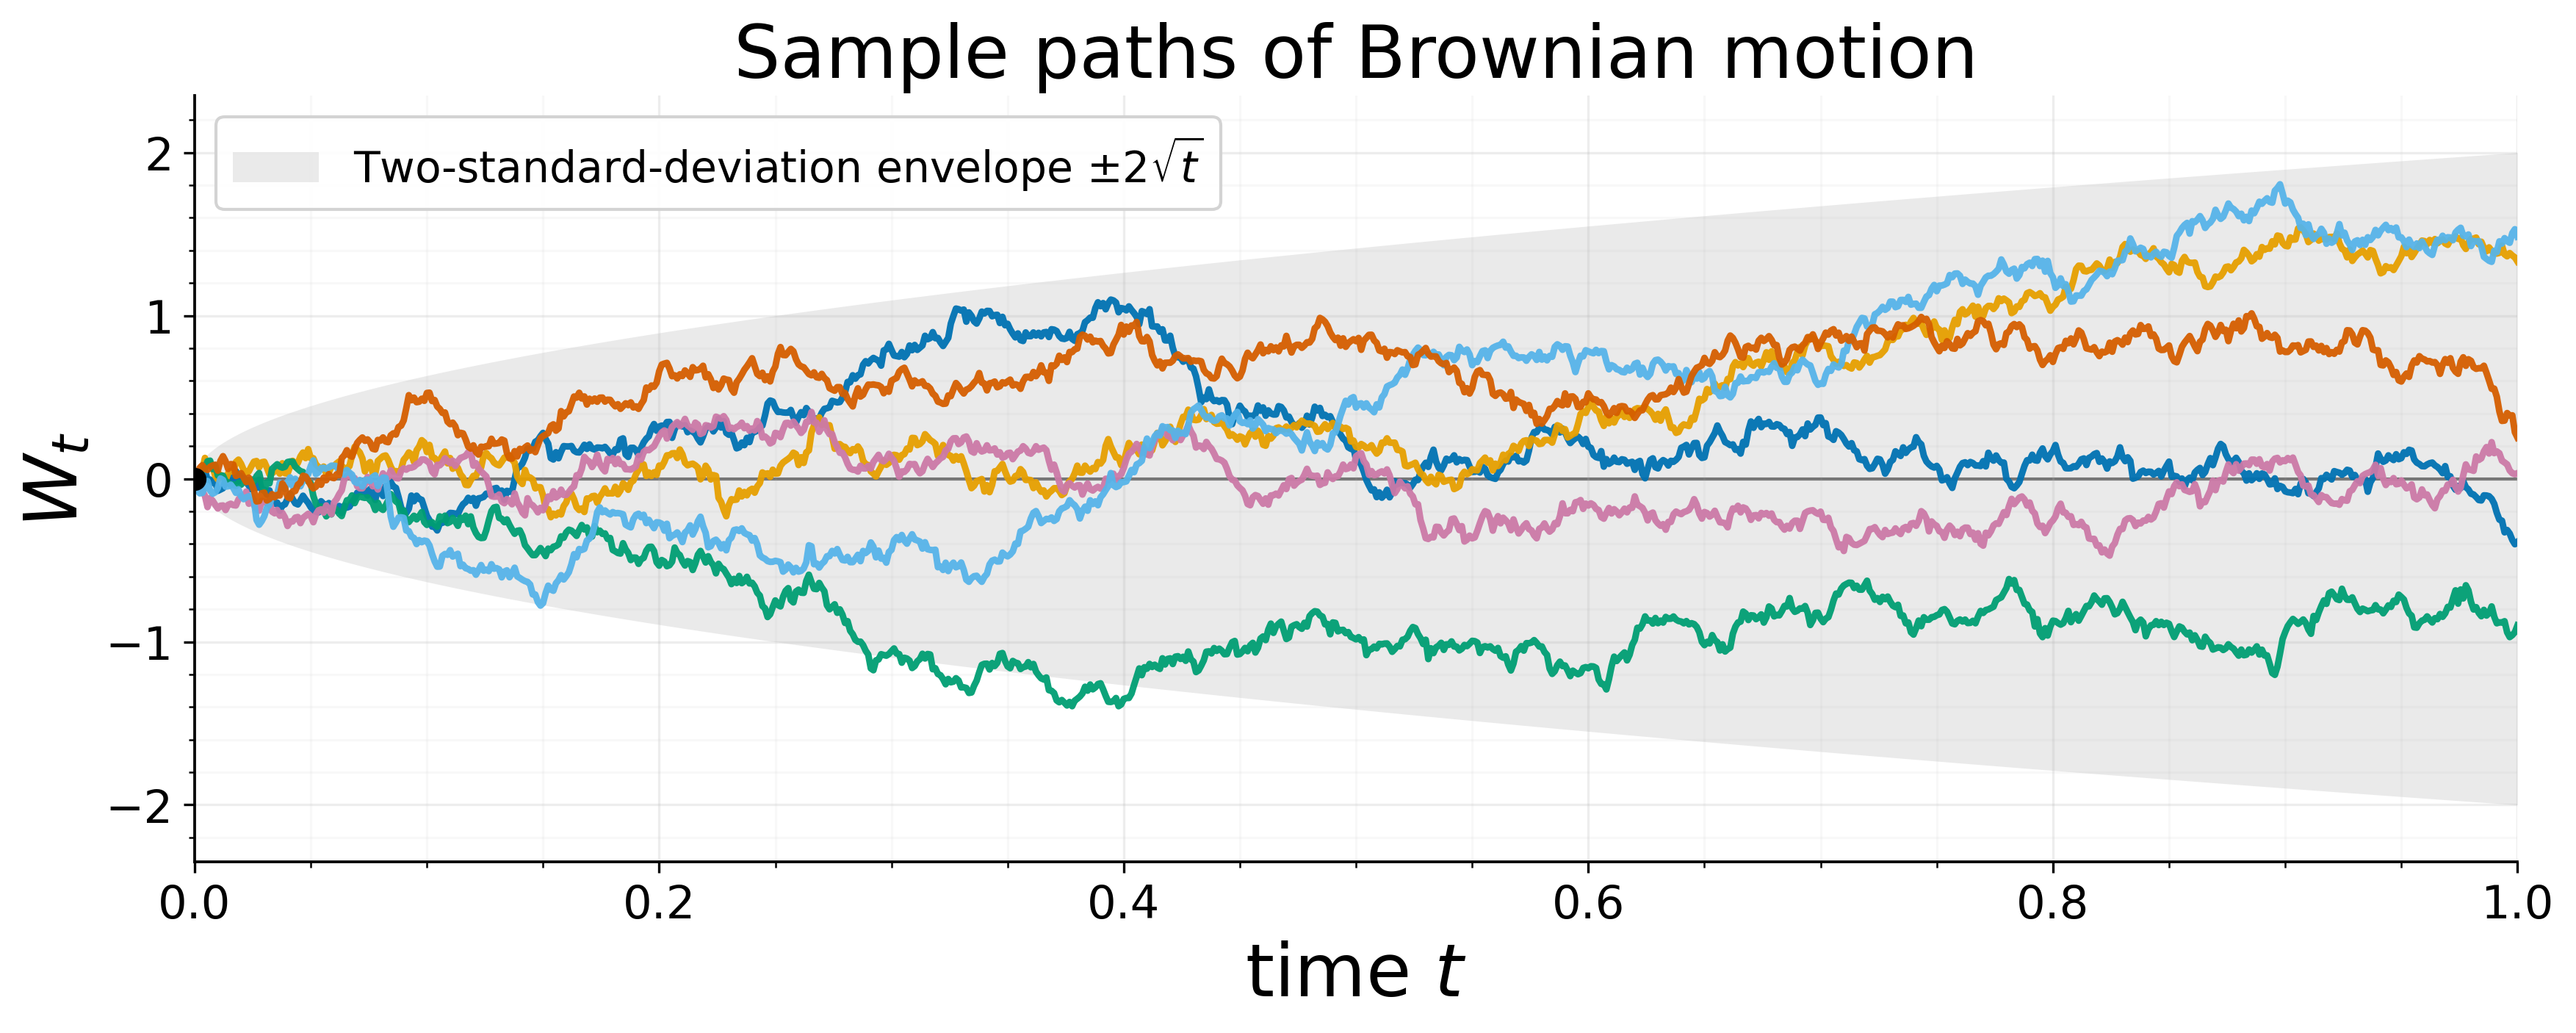

Saved PDF: figures/background/background_brownian_paths.pdf
Saved PNG: figures/background/background_brownian_paths.png


('figures/background/background_brownian_paths.pdf',
 'figures/background/background_brownian_paths.png')

In [3]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def make_brownian_paths(
    seed=4,
    T=1.0,
    n_steps=900,
    n_paths=6,
    envelope_scale=2.0,
    fig_width=12.0,
    fig_height=5.0,
    dpi=300,
    save_dpi=300,
    out_prefix="background_brownian_paths",
    out_dir=".",
    show=True,
):
    """
    Generate sample paths of one-dimensional Brownian motion.

    Saves:
        {out_dir}/{out_prefix}.pdf
        {out_dir}/{out_prefix}.png
    """

    rng = np.random.default_rng(seed)

    style = {
        "font.family": "DejaVu Sans",
        "font.size": 17,
        "axes.titlesize": 24,
        "axes.labelsize": 24,
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
        "legend.fontsize": 14,
        "axes.linewidth": 0.9,
        "mathtext.fontset": "dejavusans",
        "figure.dpi": dpi,
        "savefig.dpi": save_dpi,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }

    colors = [
        "#0072B2",  # blue
        "#E69F00",  # orange
        "#009E73",  # green
        "#CC79A7",  # purple/pink
        "#56B4E9",  # light blue
        "#D55E00",  # vermillion
    ]

    os.makedirs(out_dir, exist_ok=True)
    pdf_path = os.path.join(out_dir, f"{out_prefix}.pdf")
    png_path = os.path.join(out_dir, f"{out_prefix}.png")

    with mpl.rc_context(style):
        # --------------------------------------------------------------
        # Simulate Brownian motion
        # --------------------------------------------------------------
        t = np.linspace(0.0, T, n_steps + 1)
        dt = T / n_steps

        increments = np.sqrt(dt) * rng.normal(size=(n_paths, n_steps))
        W = np.zeros((n_paths, n_steps + 1))
        W[:, 1:] = np.cumsum(increments, axis=1)

        # --------------------------------------------------------------
        # Plot
        # --------------------------------------------------------------
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))

        upper = envelope_scale * np.sqrt(t)
        lower = -envelope_scale * np.sqrt(t)

        ax.fill_between(
            t,
            lower,
            upper,
            color="0.82",
            alpha=0.45,
            lw=0,
            zorder=0,
        )

        ax.axhline(0.0, color="0.15", lw=1.0, alpha=0.65, zorder=1)

        for i in range(n_paths):
            ax.plot(
                t,
                W[i],
                color=colors[i % len(colors)],
                lw=2.15,
                alpha=0.95,
                zorder=2,
            )

        ax.scatter([0.0], [0.0], s=42, color="black", zorder=5)

        ax.set_title("Sample paths of Brownian motion")
        ax.set_xlabel(r"time $t$")
        ax.set_ylabel(r"$W_t$")

        ax.set_xlim(0.0, T)
        ymax = max(2.35, 1.12 * np.max(np.abs(W)))
        ax.set_ylim(-ymax, ymax)

        ax.grid(True, which="major", alpha=0.22)
        ax.grid(True, which="minor", alpha=0.08)
        ax.minorticks_on()

        legend_handles = [
            Patch(
                facecolor="0.82",
                edgecolor="none",
                alpha=0.45,
                label=rf"Two-standard-deviation envelope $\pm {envelope_scale:g}\sqrt{{t}}$",
            ),
        ]

        ax.legend(
            handles=legend_handles,
            loc="upper left",
            frameon=True,
            framealpha=0.94,
            facecolor="white",
            edgecolor="0.82",
        )

        fig.tight_layout()
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, bbox_inches="tight")

        if show:
            plt.show()

        plt.close(fig)

    print(f"Saved PDF: {pdf_path}")
    print(f"Saved PNG: {png_path}")

    return pdf_path, png_path


# Example call
make_brownian_paths(
    out_dir="figures/background",
    out_prefix="background_brownian_paths",
    show=True,
)

## Figure 2.2

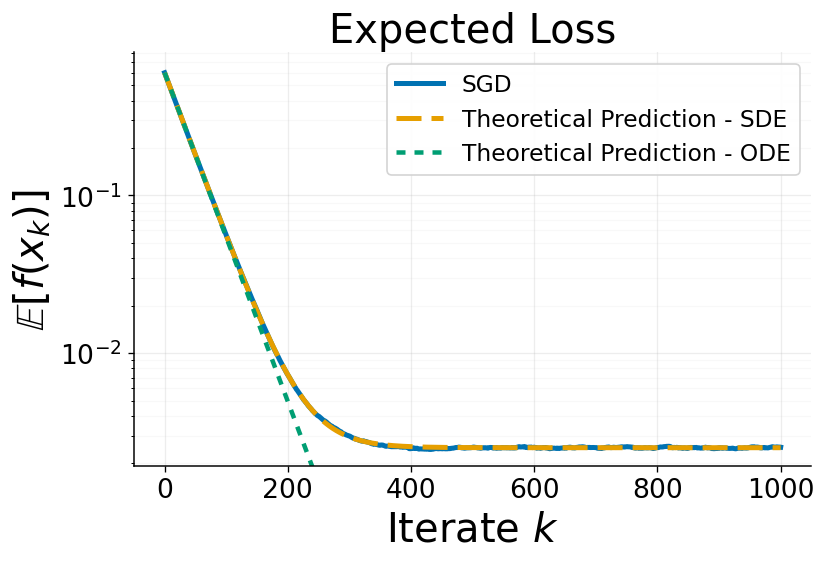

Saved PDF: figures/background/background_quadratic_sgd_loss.pdf
Saved PNG: figures/background/background_quadratic_sgd_loss.png


('figures/background/background_quadratic_sgd_loss.pdf',
 'figures/background/background_quadratic_sgd_loss.png')

In [4]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt


def make_quadratic_sgd_loss_only(
    seed=7,
    lam=1.2,
    eta=0.010,
    sigma_g2=1.0,
    B=1,
    x0=1.0,
    steps=1000,
    n_paths=12000,
    band_std_scale=0.01,   # band = mean ± band_std_scale * std
    fig_width=7.2,
    fig_height=5.0,
    dpi=120,
    save_dpi=300,
    out_dir=os.path.join("figures", "background"),
    out_prefix="background_quadratic_sgd_loss",
    show=True,
):
    """
    Simulate discrete SGD on the one-dimensional quadratic

        f_lambda(x) = (lambda / 2) x^2.

    SGD update:

        x_{k+1} = x_k - eta (lambda x_k + xi_k),

    where E[xi_k] = 0 and Var[xi_k] = Sigma = sigma_g2 / B.

    Exact discrete prediction:

        E[f_lambda(x_k)]
        = (1 - eta lambda)^{2k} f_lambda(x0)
          + (lambda eta^2 Sigma / 2)
            * (1 - (1 - eta lambda)^{2k})
              / (1 - (1 - eta lambda)^2).

    Saves:
        {out_dir}/{out_prefix}.pdf
        {out_dir}/{out_prefix}.png
    """

    rng = np.random.default_rng(seed)

    os.makedirs(out_dir, exist_ok=True)
    pdf_path = os.path.join(out_dir, f"{out_prefix}.pdf")
    png_path = os.path.join(out_dir, f"{out_prefix}.png")

    Sigma = sigma_g2 / B

    if abs(1.0 - eta * lam) >= 1.0:
        raise ValueError(
            "The quadratic SGD recursion is unstable for these parameters. "
            "Need |1 - eta * lam| < 1, i.e. 0 < eta * lam < 2."
        )

    style = {
        "font.family": "DejaVu Sans",
        "font.size": 17,
        "axes.titlesize": 24,
        "axes.labelsize": 24,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 14,
        "lines.linewidth": 3.2,
        "axes.linewidth": 0.9,
        "mathtext.fontset": "dejavusans",
        "figure.dpi": dpi,
        "savefig.dpi": save_dpi,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }

    COL = {
        "simulation": "#0072B2",
        "theory": "#E69F00",
        "gradient_flow": "#009E73",
        "band": "#0072B2",
    }

    with mpl.rc_context(style):
        k_grid = np.arange(steps + 1)
        t_grid = eta * k_grid

        x = np.zeros((n_paths, steps + 1))
        x[:, 0] = x0

        for k in range(steps):
            xi = np.sqrt(Sigma) * rng.normal(size=n_paths)
            x[:, k + 1] = x[:, k] - eta * (lam * x[:, k] + xi)

        def f(x):
            return 0.5 * lam * x**2

        loss = f(x)
        loss_mean_emp = loss.mean(axis=0)
        loss_std_emp = loss.std(axis=0)

        loss_lo = loss_mean_emp - band_std_scale * loss_std_emp
        loss_hi = loss_mean_emp + band_std_scale * loss_std_emp

        f0 = f(x0)
        rho = 1.0 - eta * lam
        rho2k = rho ** (2 * k_grid)

        denom = 1.0 - rho**2
        loss_theory = (
            rho2k * f0
            + 0.5 * lam * eta**2 * Sigma * (1.0 - rho2k) / denom
        )

        loss_gradient_flow = f0 * np.exp(-2.0 * lam * t_grid)

        fig, ax = plt.subplots(figsize=(fig_width, fig_height))

        ax.fill_between(
            k_grid,
            loss_lo,
            loss_hi,
            color=COL["band"],
            alpha=0.18,
            lw=0,
        )

        ax.plot(
            k_grid,
            loss_mean_emp,
            color=COL["simulation"],
            lw=3.0,
            label="SGD",
        )

        ax.plot(
            k_grid,
            loss_theory,
            color=COL["theory"],
            lw=3.0,
            linestyle=(0, (5, 2)),
            label="Theoretical Prediction - SDE",
        )

        ax.plot(
            k_grid,
            loss_gradient_flow,
            color=COL["gradient_flow"],
            lw=2.7,
            linestyle=(0, (2, 2)),
            label="Theoretical Prediction - ODE",
        )

        ax.set_yscale("log")
        ax.set_title("Expected Loss")
        ax.set_xlabel(r"Iterate $k$")
        ax.set_ylabel(r"$\mathbb{E}[f(x_k)]$")

        ax.grid(True, which="major", alpha=0.22)
        ax.grid(True, which="minor", alpha=0.08)

        ax.legend(
            loc="upper right",
            frameon=True,
            framealpha=0.93,
            facecolor="white",
            edgecolor="0.82",
        )

        positive_lo = loss_lo[loss_lo > 0]
        ymin = max(positive_lo.min() * 0.8 if len(positive_lo) > 0 else 1e-4, 1e-4)
        ymax = max(f0 * 1.35, loss_mean_emp.max() * 1.20)
        ax.set_ylim(ymin, ymax)

        fig.tight_layout()
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, bbox_inches="tight")

        if show:
            plt.show()

        plt.close(fig)

    print(f"Saved PDF: {pdf_path}")
    print(f"Saved PNG: {png_path}")

    return pdf_path, png_path


make_quadratic_sgd_loss_only()

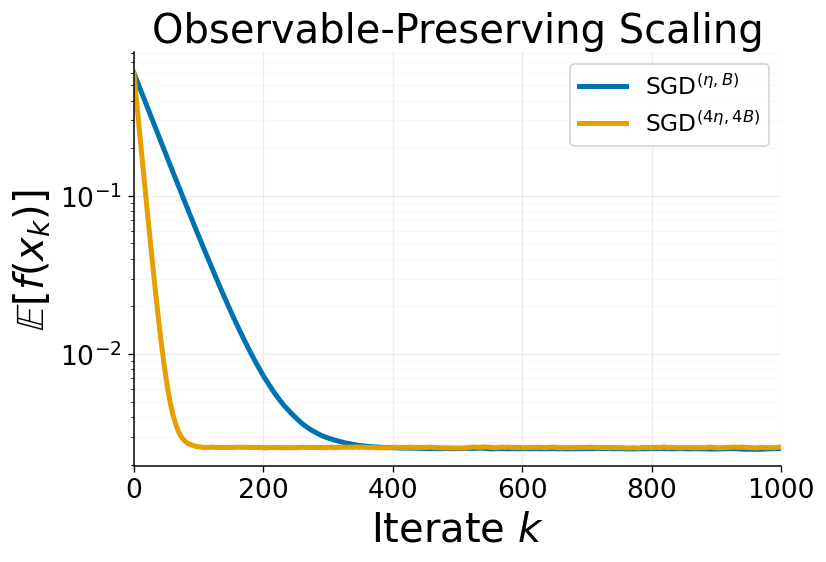

Saved PDF: figures/background/background_sgd_scaling_law_quadratic_iterates.pdf
Saved PNG: figures/background/background_sgd_scaling_law_quadratic_iterates.png

Sanity check:
  exact discrete floor, SGD(eta,B):              0.00251509
  exact discrete floor, SGD(kappa*eta,kappa*B): 0.00256148
  SDE-predicted preserved floor:                0.0025


('figures/background/background_sgd_scaling_law_quadratic_iterates.pdf',
 'figures/background/background_sgd_scaling_law_quadratic_iterates.png')

In [5]:
import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt


def make_sgd_scaling_law_quadratic_iterates(
    seed=13,
    lam=1.2,
    eta=0.01,
    sigma_g2=1.0,
    B=1,
    kappa=4,
    x0=1.0,
    steps=1000,
    n_paths=160000,
    band_std_scale=0.01,
    fig_width=7.2,
    fig_height=5.0,
    dpi=120,
    save_dpi=300,
    out_dir=os.path.join("figures", "background"),
    out_prefix="background_sgd_scaling_law_quadratic_iterates",
    show=True,
):
    """
    Compare SGD(eta, B) and SGD(kappa*eta, kappa*B) on the 1D quadratic

        f(x) = (lambda / 2) x^2.

    Single-sample gradient-noise variance is fixed at sigma_g2.

    Baseline:
        x_{k+1} = x_k - eta (lambda x_k + xi_k),
        Var[xi_k] = sigma_g2 / B.

    Rescaled:
        x_{k+1} = x_k - kappa*eta (lambda x_k + xi_k),
        Var[xi_k] = sigma_g2 / (kappa*B).

    The two curves are plotted against the SAME iteration index k.
    Therefore the rescaled method is shown as moving faster per plotted update.

    Saves:
        {out_dir}/{out_prefix}.pdf
        {out_dir}/{out_prefix}.png
    """

    rng = np.random.default_rng(seed)

    os.makedirs(out_dir, exist_ok=True)
    pdf_path = os.path.join(out_dir, f"{out_prefix}.pdf")
    png_path = os.path.join(out_dir, f"{out_prefix}.png")

    eta_scaled = kappa * eta
    B_scaled = kappa * B

    Sigma_base = sigma_g2 / B
    Sigma_scaled = sigma_g2 / B_scaled

    if not (0.0 < eta * lam < 2.0):
        raise ValueError("Baseline SGD is unstable: need 0 < eta * lam < 2.")
    if not (0.0 < eta_scaled * lam < 2.0):
        raise ValueError("Scaled SGD is unstable: need 0 < kappa * eta * lam < 2.")

    style = {
        "font.family": "DejaVu Sans",
        "font.size": 17,
        "axes.titlesize": 24,
        "axes.labelsize": 24,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "legend.fontsize": 14,
        "lines.linewidth": 3.2,
        "axes.linewidth": 0.9,
        "mathtext.fontset": "dejavusans",
        "figure.dpi": dpi,
        "savefig.dpi": save_dpi,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }

    COL = {
        "base": "#0072B2",
        "scaled": "#E69F00",
        "band_base": "#0072B2",
        "band_scaled": "#E69F00",
    }

    def f(x):
        return 0.5 * lam * x**2

    def simulate_sgd(eta_, Sigma_):
        x = np.zeros((n_paths, steps + 1))
        x[:, 0] = x0

        for k in range(steps):
            xi = np.sqrt(Sigma_) * rng.normal(size=n_paths)
            x[:, k + 1] = x[:, k] - eta_ * (lam * x[:, k] + xi)

        return f(x)

    def exact_discrete_stationary_loss(eta_, Sigma_):
        """
        Exact stationary expected loss for the stable recursion

            x_{k+1} = (1 - eta lambda) x_k - eta xi_k.

        Var[x_infty] = eta^2 Sigma / (1 - (1 - eta lambda)^2)
        E[f(x_infty)] = lambda Var[x_infty] / 2.
        """
        rho = 1.0 - eta_ * lam
        return 0.5 * lam * eta_**2 * Sigma_ / (1.0 - rho**2)

    with mpl.rc_context(style):
        k_grid = np.arange(steps + 1)

        # --------------------------------------------------------------
        # Simulate both SGD methods for the same number of iterations.
        # --------------------------------------------------------------
        loss_base = simulate_sgd(eta, Sigma_base)
        loss_scaled = simulate_sgd(eta_scaled, Sigma_scaled)

        mean_base = loss_base.mean(axis=0)
        std_base = loss_base.std(axis=0)
        lo_base = np.maximum(mean_base - band_std_scale * std_base, 1e-12)
        hi_base = mean_base + band_std_scale * std_base

        mean_scaled = loss_scaled.mean(axis=0)
        std_scaled = loss_scaled.std(axis=0)
        lo_scaled = np.maximum(mean_scaled - band_std_scale * std_scaled, 1e-12)
        hi_scaled = mean_scaled + band_std_scale * std_scaled

        # Not plotted: useful sanity check.
        floor_base_discrete = exact_discrete_stationary_loss(eta, Sigma_base)
        floor_scaled_discrete = exact_discrete_stationary_loss(eta_scaled, Sigma_scaled)
        floor_sde = eta * sigma_g2 / (4.0 * B)

        # --------------------------------------------------------------
        # Plot
        # --------------------------------------------------------------
        fig, ax = plt.subplots(figsize=(fig_width, fig_height))

        # Thin bands, no legend entries.
        ax.fill_between(
            k_grid,
            lo_base,
            hi_base,
            color=COL["band_base"],
            alpha=0.14,
            lw=0,
        )

        ax.fill_between(
            k_grid,
            lo_scaled,
            hi_scaled,
            color=COL["band_scaled"],
            alpha=0.14,
            lw=0,
        )

        ax.plot(
            k_grid,
            mean_base,
            color=COL["base"],
            lw=3.0,
            label=rf"$\mathrm{{SGD}}^{{(\eta,B)}}$",
        )

        ax.plot(
            k_grid,
            mean_scaled,
            color=COL["scaled"],
            lw=3.0,
            label=rf"$\mathrm{{SGD}}^{{({kappa}\eta,{kappa}B)}}$",
        )

        ax.set_yscale("log")
        ax.set_title("Observable-Preserving Scaling")
        ax.set_xlabel(r"Iterate $k$")
        ax.set_ylabel(r"$\mathbb{E}[f(x_k)]$")

        ax.grid(True, which="major", alpha=0.22)
        ax.grid(True, which="minor", alpha=0.08)

        ax.legend(
            loc="upper right",
            frameon=True,
            framealpha=0.93,
            facecolor="white",
            edgecolor="0.82",
        )

        positive_vals = np.concatenate([
            lo_base[lo_base > 0],
            lo_scaled[lo_scaled > 0],
        ])
        ymin = max(positive_vals.min() * 0.8 if len(positive_vals) > 0 else 1e-5, 1e-5)
        ymax = max(mean_base.max(), mean_scaled.max(), f(x0)) * 1.35

        ax.set_ylim(ymin, ymax)
        ax.set_xlim(0, steps)

        fig.tight_layout()
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, bbox_inches="tight")

        if show:
            plt.show()

        plt.close(fig)

    print(f"Saved PDF: {pdf_path}")
    print(f"Saved PNG: {png_path}")
    print()
    print("Sanity check:")
    print(f"  exact discrete floor, SGD(eta,B):              {floor_base_discrete:.6g}")
    print(f"  exact discrete floor, SGD(kappa*eta,kappa*B): {floor_scaled_discrete:.6g}")
    print(f"  SDE-predicted preserved floor:                {floor_sde:.6g}")

    return pdf_path, png_path


make_sgd_scaling_law_quadratic_iterates()

## Figure 3.1

saved: figures/fig04_flat_vs_sharp_minima.png
saved: figures/fig04_flat_vs_sharp_minima.pdf


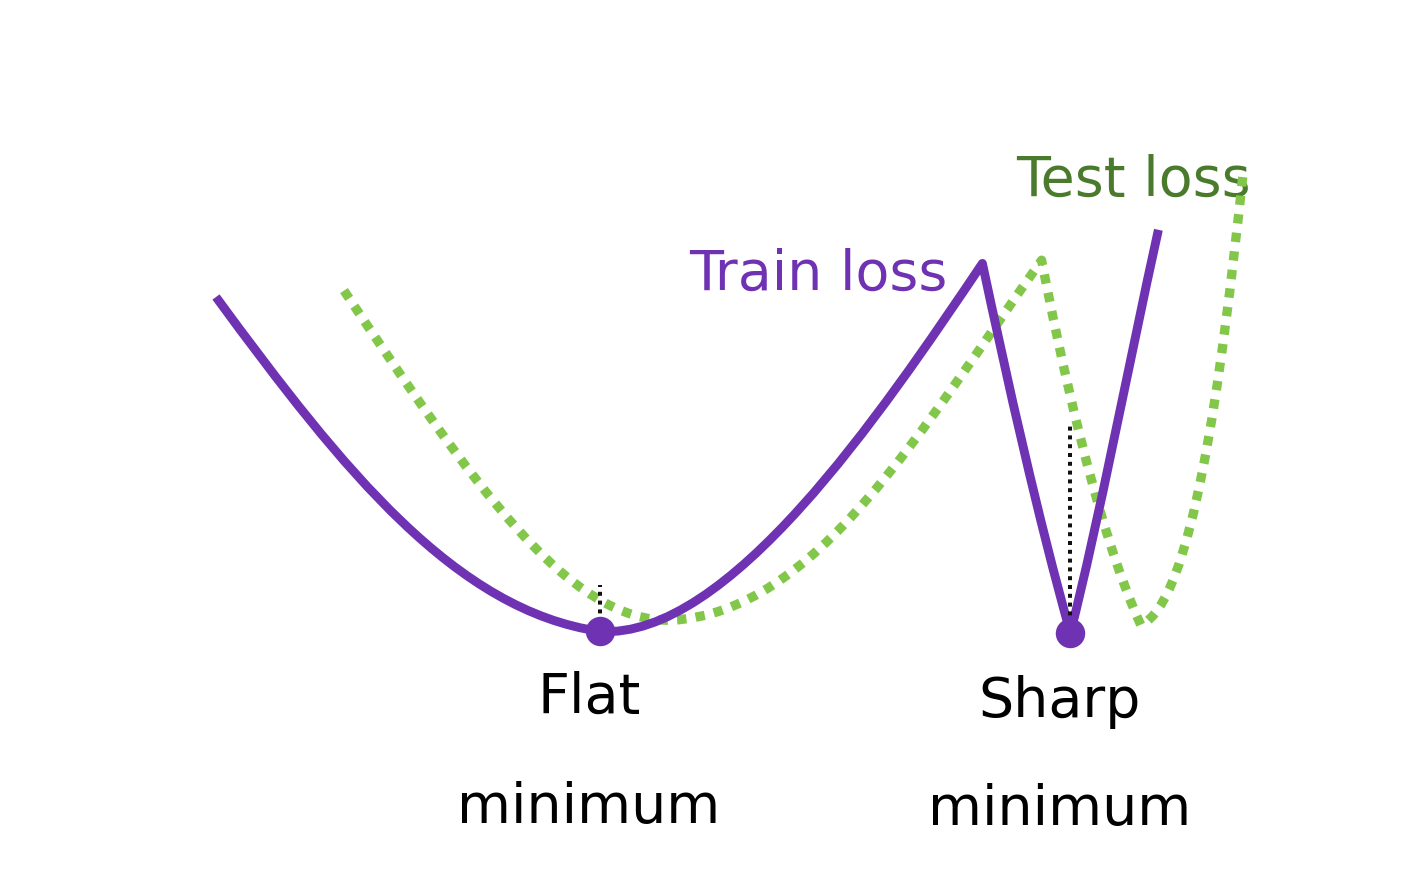

saved: figures/fig03_sam_extrastep.png
saved: figures/fig03_sam_extrastep.pdf


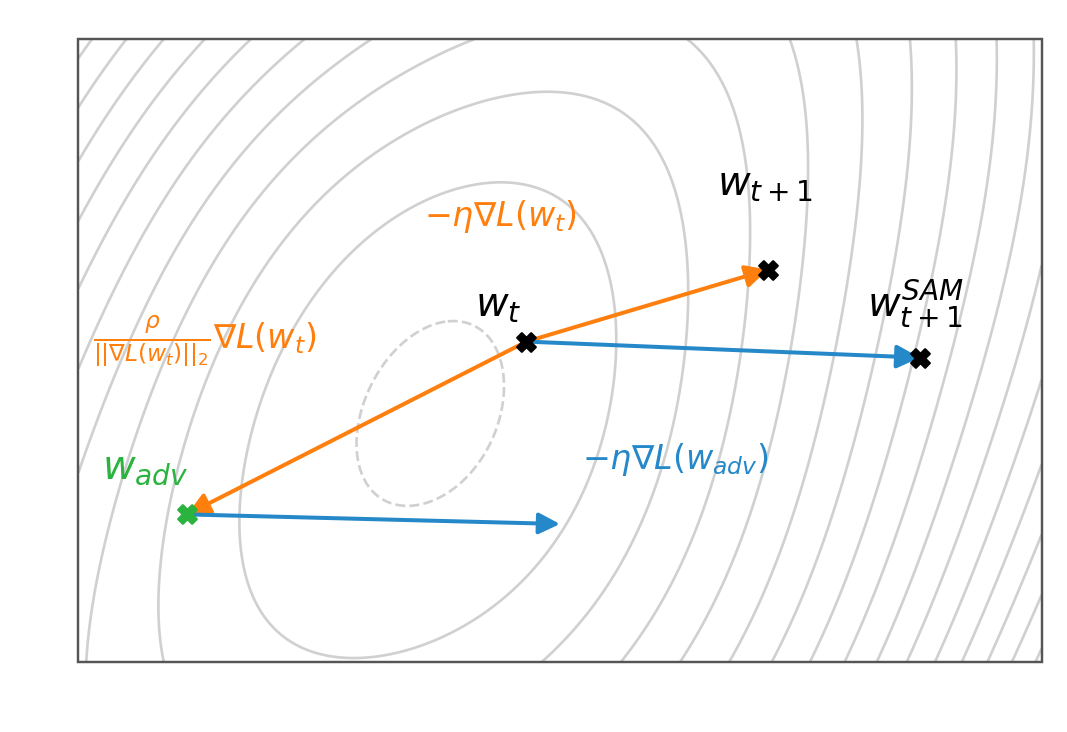

In [6]:
# ============================================================
# Drop-in replacement for the original notebook.
# This intentionally replicates the two reference figures you sent:
#   1) Flat vs sharp minima
#   2) SAM update schematic
#
# Copy-paste this cell and run it.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "axes.unicode_minus": False,
})

# ------------------------------------------------------------
# Save helper: uses your notebook's savefig(fig, name) if present.
# ------------------------------------------------------------
def _save_thesis_fig(fig, name):
    if "savefig" in globals():
        try:
            savefig(fig, name)
            return
        except Exception:
            pass

    fig.savefig(f"{name}.png", dpi=300, bbox_inches="tight", pad_inches=0.01)
    fig.savefig(f"{name}.pdf", bbox_inches="tight", pad_inches=0.01)


# ------------------------------------------------------------
# Helper for Bezier paths
# ------------------------------------------------------------
def _draw_bezier_path(ax, verts, codes, color, lw=4.0, ls="solid", zorder=5):
    path = Path(verts, codes)
    patch = PathPatch(
        path,
        facecolor="none",
        edgecolor=color,
        lw=lw,
        linestyle=ls,
        capstyle="butt",
        joinstyle="round",
        zorder=zorder,
    )
    ax.add_patch(patch)
    return patch


# ============================================================
# Figure 04: Flat vs sharp minima
# Replicates the screenshot you sent.
# ============================================================
def make_fig04_flat_vs_sharp_minima():
    purple = "#6f32b2"
    green = "#83c74a"
    black = "#111111"

    # Same aspect ratio as your screenshot: 870 x 526.
    fig, ax = plt.subplots(figsize=(8.70, 5.26), dpi=160)
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

    ax.set_xlim(0, 870)
    ax.set_ylim(526, 0)
    ax.axis("off")

    # --------------------------------------------------------
    # Purple training-loss curve.
    # One continuous Bezier path: broad flat basin, then sharp basin.
    # Coordinates are in "pixel-like" units so you can edit visually.
    # --------------------------------------------------------
    train_verts = [
        (125, 176),

        # Broad basin down to flat minimum.
        (205, 285),
        (275, 372),
        (365, 385),

        # Broad basin rises toward the sharp region.
        (445, 390),
        (540, 250),
        (604, 155),

        # Sharp basin left wall.
        (620, 230),
        (639, 315),
        (659, 386),

        # Sharp basin right wall.
        (677, 315),
        (695, 220),
        (714, 134),
    ]
    train_codes = [Path.MOVETO] + [Path.CURVE4] * 12

    _draw_bezier_path(
        ax,
        train_verts,
        train_codes,
        color=purple,
        lw=4.0,
        ls="solid",
        zorder=6,
    )

    # --------------------------------------------------------
    # Green dotted test-loss curve.
    # --------------------------------------------------------
    test_verts = [
        (205, 172),

        # Test curve around flat minimum.
        (285, 292),
        (345, 380),
        (410, 378),

        # Rises toward the sharp region.
        (500, 373),
        (565, 260),
        (641, 153),

        # Drops around the sharp training minimum.
        (652, 210),
        (675, 320),
        (703, 381),

        # Rises again sharply.
        (735, 367),
        (753, 230),
        (767, 98),
    ]
    test_codes = [Path.MOVETO] + [Path.CURVE4] * 12

    _draw_bezier_path(
        ax,
        test_verts,
        test_codes,
        color=green,
        lw=4.2,
        ls=(0, (1.0, 1.0)),
        zorder=5,
    )

    # --------------------------------------------------------
    # Minima markers and dotted vertical gaps.
    # --------------------------------------------------------
    flat_min = (365, 385)
    sharp_min = (659, 386)

    ax.scatter(
        [flat_min[0], sharp_min[0]],
        [flat_min[1], sharp_min[1]],
        s=150,
        color=purple,
        zorder=10,
    )

    ax.plot(
        [365, 365],
        [385, 356],
        color=black,
        lw=1.8,
        ls=(0, (1.0, 1.2)),
        zorder=8,
    )

    ax.plot(
        [659, 659],
        [386, 255],
        color=black,
        lw=1.8,
        ls=(0, (1.0, 1.2)),
        zorder=8,
    )

    # --------------------------------------------------------
    # Text labels.
    # --------------------------------------------------------
    ax.text(
        421,
        162,
        "Train loss",
        color=purple,
        fontsize=25,
        ha="left",
        va="center",
    )

    ax.text(
        625,
        103,
        "Test loss",
        color="#4a7b2c",
        fontsize=25,
        ha="left",
        va="center",
    )

    ax.text(
        358,
        426,
        "Flat",
        fontsize=25,
        color="black",
        ha="center",
        va="center",
    )

    ax.text(
        358,
        495,
        "minimum",
        fontsize=25,
        color="black",
        ha="center",
        va="center",
    )

    ax.text(
        652,
        429,
        "Sharp",
        fontsize=25,
        color="black",
        ha="center",
        va="center",
    )

    ax.text(
        652,
        496,
        "minimum",
        fontsize=25,
        color="black",
        ha="center",
        va="center",
    )

    _save_thesis_fig(fig, "fig04_flat_vs_sharp_minima")
    plt.show()
    plt.close(fig)


# ============================================================
# Figure 03: SAM update schematic
# Replicates the Foret-style SAM update diagram you sent.
# ============================================================
def make_fig03_sam_extrastep():
    orange = "#ff7f0e"
    blue = "#2588c8"
    green = "#2bb33f"
    gray = "#bfbfbf"
    box_gray = "#555555"

    # Same aspect ratio as your screenshot: 647 x 438.
    fig, ax = plt.subplots(figsize=(6.47, 4.38), dpi=160)
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

    ax.set_xlim(0, 647)
    ax.set_ylim(438, 0)
    ax.axis("off")

    # --------------------------------------------------------
    # Plot box dimensions, chosen to match the screenshot.
    # --------------------------------------------------------
    left, top = 39, 15
    width, height = 602, 389
    right, bottom = left + width, top + height

    # --------------------------------------------------------
    # Loss-contour background.
    # This is synthetic, but shaped to resemble the reference.
    # --------------------------------------------------------
    xs = np.linspace(left, right, 450)
    ys = np.linspace(top, bottom, 340)
    X, Y = np.meshgrid(xs, ys)

    u = (X - left) / width * 2.6 - 1.3
    v = (Y - top) / height * 1.7 - 0.85

    Z = (
        0.48 * (1.15 * u + 0.55 * v + 0.10) ** 2
        + 0.13 * (-0.40 * u + 1.35 * v - 0.15) ** 2
        + 0.20 * u
        - 0.05 * v
        + 0.08 * np.sin(2.4 * u - 0.4) * np.cos(2.1 * v + 0.2)
    )

    levels = np.linspace(Z.min() + 0.03, Z.max() - 0.04, 16)

    ax.contour(
        X,
        Y,
        Z,
        levels=levels,
        colors=gray,
        linewidths=1.2,
        alpha=0.72,
        zorder=1,
    )

    # Border box.
    ax.add_patch(
        Rectangle(
            (left, top),
            width,
            height,
            fill=False,
            ec=box_gray,
            lw=1.1,
            zorder=20,
        )
    )

    # --------------------------------------------------------
    # Key points, in pixel-like coordinates.
    # --------------------------------------------------------
    w_adv = np.array([107, 312])
    w_t = np.array([319, 204])
    w_next = np.array([470, 159])
    w_sam = np.array([565, 214])
    blue_direction_end = np.array([340, 318])

    def _arrow(p0, p1, color, lw=1.8, ms=20, z=10):
        ax.annotate(
            "",
            xy=p1,
            xytext=p0,
            arrowprops=dict(
                arrowstyle="-|>",
                color=color,
                lw=lw,
                mutation_scale=ms,
                shrinkA=0,
                shrinkB=0,
            ),
            zorder=z,
        )

    # --------------------------------------------------------
    # Orange arrows:
    #   - perturb from w_t to w_adv
    #   - ordinary gradient step from w_t to w_{t+1}
    # --------------------------------------------------------
    _arrow(w_t, w_adv, orange, lw=1.8, ms=21)
    _arrow(w_t, w_next, orange, lw=1.8, ms=21)

    # --------------------------------------------------------
    # Blue arrows:
    #   - gradient evaluated at w_adv
    #   - SAM update applied from w_t
    # --------------------------------------------------------
    _arrow(w_adv, blue_direction_end, blue, lw=1.8, ms=20)
    _arrow(w_t, w_sam, blue, lw=1.8, ms=22)

    # --------------------------------------------------------
    # Markers.
    # --------------------------------------------------------
    ax.scatter(
        *w_adv,
        marker="X",
        s=70,
        color=green,
        linewidths=1.0,
        zorder=30,
    )

    ax.scatter(
        *w_t,
        marker="X",
        s=70,
        color="black",
        linewidths=1.0,
        zorder=30,
    )

    ax.scatter(
        *w_next,
        marker="X",
        s=70,
        color="black",
        linewidths=1.0,
        zorder=30,
    )

    ax.scatter(
        *w_sam,
        marker="X",
        s=70,
        color="black",
        linewidths=1.0,
        zorder=30,
    )

    # --------------------------------------------------------
    # Labels.
    # --------------------------------------------------------
    ax.text(
        287,
        188,
        r"$w_t$",
        fontsize=18,
        color="black",
        zorder=40,
    )

    ax.text(
        438,
        112,
        r"$w_{t+1}$",
        fontsize=18,
        color="black",
        zorder=40,
    )

    ax.text(
        532,
        188,
        r"$w^{SAM}_{t+1}$",
        fontsize=18,
        color="black",
        zorder=40,
    )

    ax.text(
        54,
        289,
        r"$w_{adv}$",
        fontsize=18,
        color=green,
        zorder=40,
    )

    ax.text(
        255,
        131,
        r"$-\eta\nabla L(w_t)$",
        fontsize=15,
        color=orange,
        zorder=40,
    )

    ax.text(
        48,
        208,
        r"$\frac{\rho}{||\nabla L(w_t)||_2}\nabla L(w_t)$",
        fontsize=15,
        color=orange,
        zorder=40,
    )

    ax.text(
        354,
        283,
        r"$-\eta\nabla L(w_{adv})$",
        fontsize=15,
        color=blue,
        zorder=40,
    )

    _save_thesis_fig(fig, "fig03_sam_extrastep")
    plt.show()
    plt.close(fig)


# ============================================================
# Run
# ============================================================
make_fig04_flat_vs_sharp_minima()
make_fig03_sam_extrastep()

## Figure 5.2



saved: figures/fig07_signsgd_three_phases.png
saved: figures/fig07_signsgd_three_phases.pdf


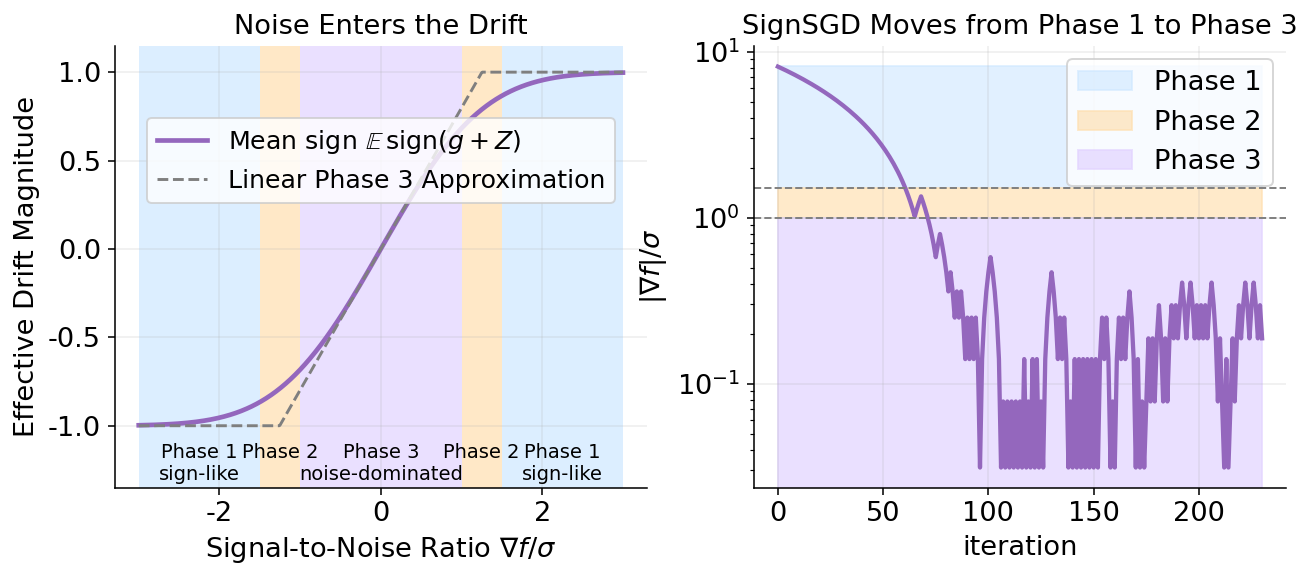

In [7]:
import math
import numpy as np
import matplotlib.pyplot as plt

# Figure 07: SignSGD as a signal-to-noise dependent drift.
# Suggested placement: Chapter 5.3.1, before or after Lemma 5.3.

def make_fig07_signsgd_three_phases():
    FS = 14              # default font size for almost everything
    PHASE_FS = 10        # font size for phase labels in Panel A
    LEFT_LEGEND_FS = 13  # font size for left-panel legend

    r = np.linspace(-3.0, 3.0, 700)
    erf_vec = np.vectorize(math.erf)
    drift = erf_vec(r / np.sqrt(2.0))
    linear = np.sqrt(2 / np.pi) * r

    # Slightly more visible phase colors
    phase1_col = "#cfe8ff"   # more visible light blue
    phase2_col = "#ffe0b2"   # more visible light orange
    phase3_col = "#e3d5ff"   # more visible light purple

    with plt.rc_context({
        "font.size": FS,
        "axes.labelsize": FS,
        "axes.titlesize": FS,
        "xtick.labelsize": FS,
        "ytick.labelsize": FS,
        "legend.fontsize": FS,
    }):
        fig, axs = plt.subplots(1, 2, figsize=(10.8, 4.1))

        # -------------------------
        # Panel A
        # -------------------------
        ax = axs[0]
        ax.plot(
            r, drift,
            color=COL["purple"], lw=2.4,
            label=r"Mean sign $\mathbb{E}\,\mathrm{sign}(g+Z)$"
        )
        ax.plot(
            r, np.clip(linear, -1, 1),
            color=COL["gray"], lw=1.5, ls="--",
            label="Linear Phase 3 Approximation"
        )

        phase_texts = []

        phase_specs = [
            (-3.0, -1.5, "Phase 1\nsign-like", phase1_col),
            (-1.5, -1.0, "Phase 2", phase2_col),
            (-1.0,  1.0, "Phase 3\nnoise-dominated", phase3_col),
            ( 1.0,  1.5, "Phase 2", phase2_col),
            ( 1.5,  3.0, "Phase 1\nsign-like", phase1_col),
        ]

        for lo, hi, lab, fc in phase_specs:
            ax.axvspan(lo, hi, color=fc, alpha=0.72, lw=0)
            txt = ax.text(
                (lo + hi) / 2, 0.1, lab,
                transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=PHASE_FS
            )
            phase_texts.append(txt)

        ax.set_xlabel(r"Signal-to-Noise Ratio $\nabla f/\sigma$", fontsize=FS)
        ax.set_ylabel("Effective Drift Magnitude", fontsize=FS)
        ax.set_title("Noise Enters the Drift", fontsize=FS)
        ax.set_ylim(-1.35, 1.15)
        left_legend = ax.legend(
    frameon=True,
    loc="center",
    bbox_to_anchor=(0.5, 0.5),
    bbox_transform=ax.get_yaxis_transform(),
    fontsize=LEFT_LEGEND_FS
)
        ax.tick_params(axis="both", which="both", labelsize=FS)
        ax.grid(True, alpha=0.22)

        # -------------------------
        # Panel B
        # -------------------------
        ax = axs[1]

        # Illustrative trajectory on a 1D quadratic:
        # ratio decays as optimizer approaches the minimizer.
        steps = 230
        x = np.zeros(steps + 1)
        x[0] = 2.6
        eta = 0.035
        sigma = 0.32
        lam = 1.0
        rng = np.random.default_rng(2)

        for k in range(steps):
            noisy_grad = lam * x[k] + sigma * rng.normal()
            x[k + 1] = x[k] - eta * np.sign(noisy_grad)

        ratio = np.abs(lam * x / sigma)
        t = np.arange(steps + 1)

        ax.fill_between(
            t, 1.5, ratio.max() + 0.1,
            color=phase1_col, alpha=0.62, label="Phase 1"
        )
        ax.fill_between(
            t, 1.0, 1.5,
            color=phase2_col, alpha=0.68, label="Phase 2"
        )
        ax.fill_between(
            t, 0.0, 1.0,
            color=phase3_col, alpha=0.72, label="Phase 3"
        )

        ax.plot(t, ratio, color=COL["purple"], lw=2.2)
        ax.axhline(1.5, color=COL["gray"], ls="--", lw=1)
        ax.axhline(1.0, color=COL["gray"], ls="--", lw=1)

        ax.set_yscale("log")
        ax.set_xlabel("iteration", fontsize=FS)
        ax.set_ylabel(r"$|\nabla f|/\sigma$", fontsize=FS)
        ax.set_title("SignSGD Moves from Phase 1 to Phase 3", fontsize=FS)
        ax.legend(frameon=True, loc="upper right", fontsize=FS)
        ax.tick_params(axis="both", which="both", labelsize=FS)
        ax.grid(True, alpha=0.22)

        # Force every text object in the figure to size 14
        for text in fig.findobj(match=plt.Text):
            text.set_fontsize(FS)

        # Re-apply smaller font size only to the phase labels in Panel A
        for text in phase_texts:
            text.set_fontsize(PHASE_FS)

        # Re-apply left legend fontsize = 13
        for text in left_legend.get_texts():
            text.set_fontsize(LEFT_LEGEND_FS)

        savefig(fig, "fig07_signsgd_three_phases")
        plt.show()
        plt.close(fig)

make_fig07_signsgd_three_phases()